# In Class Activity - Hypothesis testing

```{note}
This exercise authored by Brenden Lake and is released under the [license](/LICENSE.html).
```

The chapter discussed some basic issues in hypothesis testing. In this notebook, you will explore these ideas in Python.

## Importing packages

In [9]:
import numpy as np
import numpy.random as npr
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd

## Problem 0: Critical regions and critical values

Let's recreate the example from Section 10.4.1, which talks about computing the critical region for the ESP study. Here are some of the details, but I suggest you review Section 10.4.1 first.

Our population parameter $\theta$ is just the overall probability that people respond correctly when asked to guess which side of the card is displayed in the ESP study. Our test statistic $X$ is the *count* of the number of people who did so, out of a sample size of $N$.  This is exactly what the [binomial distribution](https://en.wikipedia.org/wiki/Binomial_distribution) describes! So, we would say that the null hypothesis predicts that $X$ is binomially distributed, which is written
$
X \sim \text{Binomial}(\theta,N).
$
Since the null hypothesis states that $\theta = 0.5$, and our experiment has $N=100$ people, we can use this as a sampling distribution.

Your goal here is to compute the critical region for $\alpha = .05$ (the type-I error rate) using sampling. Thus, you should randomly generate 10,000 experiments, each with $N=100$ coin flips, and record the test statistic $X$ for each simulated experiment. Your goal is to find the lower and upper "critical values" given your sampling distribution.

You may find the following functions helpful: `np.random.binomial`, `np.sort`, and `sns.displot`.

In [10]:
N = 100
no_exps = 10000
smp = np.random.binomial (N, .50, no_exps)
print (smp[:10])

[55 54 43 48 51 53 43 49 57 48]


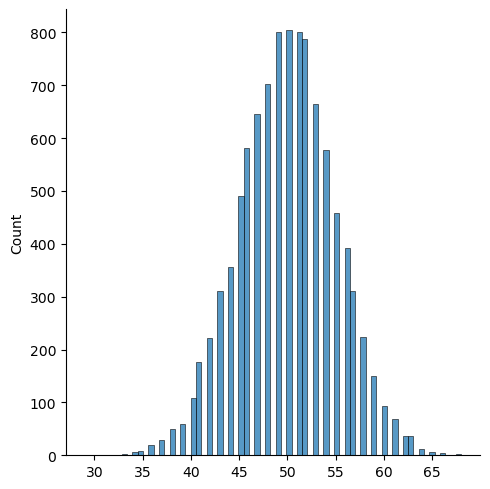

In [43]:
sns.displot (smp)

In [4]:
smp = np.sort (smp)
print (smp[:10])
print (smp[-10:])

[31 32 32 32 33 33 33 34 34 34]
[65 65 65 65 65 66 66 67 68 68]


In [5]:
lower_crit_value = np.percentile (smp, 2.5)
upper_crit_value = np.percentile (smp, 97.5)
print (lower_crit_value, upper_crit_value)

40.0 60.0


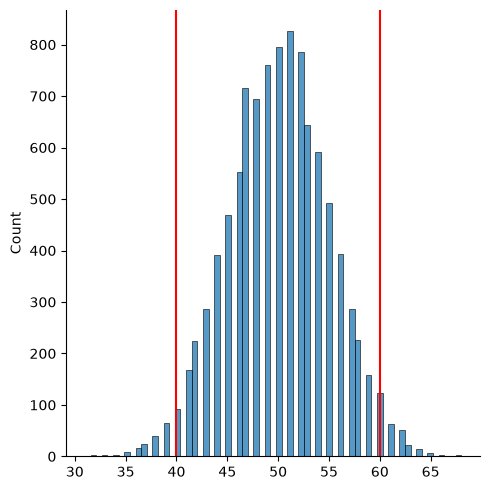

In [6]:
sns.displot (smp)
plt.axvline(x=lower_crit_value, color='red')
plt.axvline(x=upper_crit_value, color='red')

## Problem 1: Critical values and sample size

Copy the code above and see how the location of the critical values changes as a function of the number of simulated participants in an experiment. Thus, rather than $N=100$, what are the critical values when $N=200$ or $N=500$? You will want to use $X/N$ as your sample statistic instead (percent of participants that get it right) so you can compare more easily across different numbers of participants.

In [9]:
N = 200
no_exps = 10000
smp = np.random.binomial (N, .50, no_exps)
smp = [x / N for x in smp]
<Your code here>

## Problem 2: Binomial test

Note that we can test the simulated critical values in Problem 0 to see how they correspond with an exact binomial test. To do so, check out the scipy function `stats.binom_test`. Remember that in Problem 0 we found that the lower critical value was about 40 and the upper one was about 60. Look at the p values produced by `stats.binom_test` for those two values.

In [52]:
stats.binomtest (40, 100, p=.5)

BinomTestResult(k=40, n=100, alternative='two-sided', statistic=0.4, pvalue=0.05688793364098089)

In [53]:
stats.binomtest (60, 100, p=.5)

BinomTestResult(k=60, n=100, alternative='two-sided', statistic=0.6, pvalue=0.05688793364098089)

Now do the same thing for your simulation of N = 200. Do the two methods (simulation and the exact binomial test) yield consistent results? 

Suppose you ran an experiment with $N = 500$ and recorded people's binary response (e.g., 'yes' or 'no'). Assuming $\theta = 0.5$ and $\alpha = .05$, would 200 'yes' responses be considered statistically significant? How about 225, 250, 275 and 300? Which are significant if one assumes $\alpha = .01$ instead?